Deliverable 1: G6_2


Task 1: Creating a graph of temperatures through the year 2025 in Ås

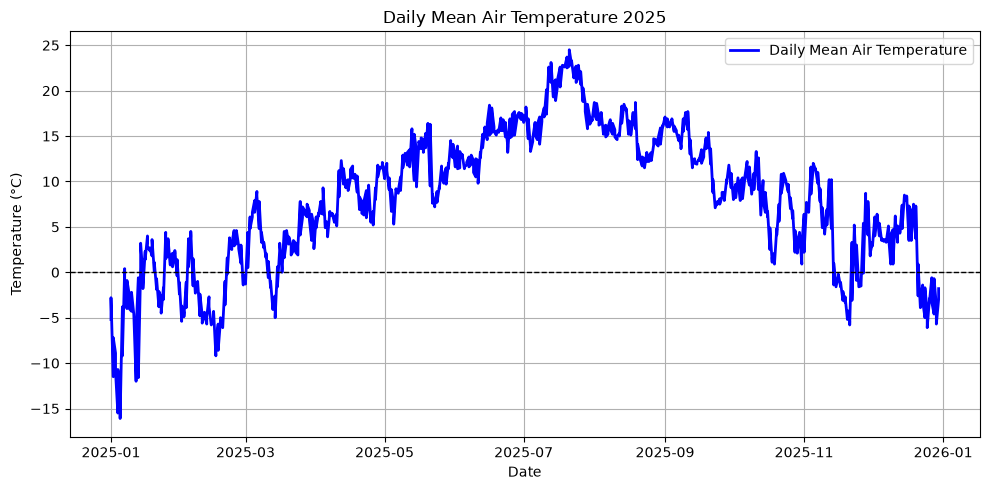

In [45]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Reading the client ID from a local file
client_path = os.path.expanduser("~/Documents/client.txt")
with open(client_path, encoding="utf-8") as client_file:
    client_id = client_file.read().strip()

endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

# Issuing a HTTP GET request to the Frost API with the specified parameters and authentication
r = requests.get(endpoint, params=parameters, auth=(client_id, ""))
json_data = r.json()

# Checking if the request was successful
if r.status_code == 200:
    # Extracting the relevant data
    data = json_data["data"]

    # Flattening the data into a list of dictionaries
    rows = []
    for entry in data:
        ref_time = entry["referenceTime"]
        for observation in entry["observations"]:
            rows.append(
                {"datetime": ref_time, "temperature": observation["value"]}
            )

    # Creating a DataFrame
    df = pd.DataFrame(rows)
    df["datetime"] = pd.to_datetime(df["datetime"])

    # Using matplotlib to plot the data
    plt.figure(figsize=(10, 5))
    plt.plot(
        df["datetime"],
        df["temperature"],
        color="blue",
        linewidth=2,
        label="Daily Mean Air Temperature",
    )
    plt.axhline(0, color="black", linewidth=1, linestyle="--")

    plt.title("Daily Mean Air Temperature 2025")
    plt.xlabel("Date")
    plt.ylabel("Temperature (°C)")
    plt.grid()
    plt.legend()
    plt.tight_layout()

    # Displaying the plot
    plt.show()

# If the request was not successful, print the error message
else:
    print(f"Error {r.status_code}: {json_data.get('error', {}).get('message')}")

Task 2: Combining the graph of temperatures through 2025, with the addition of Precipitation 

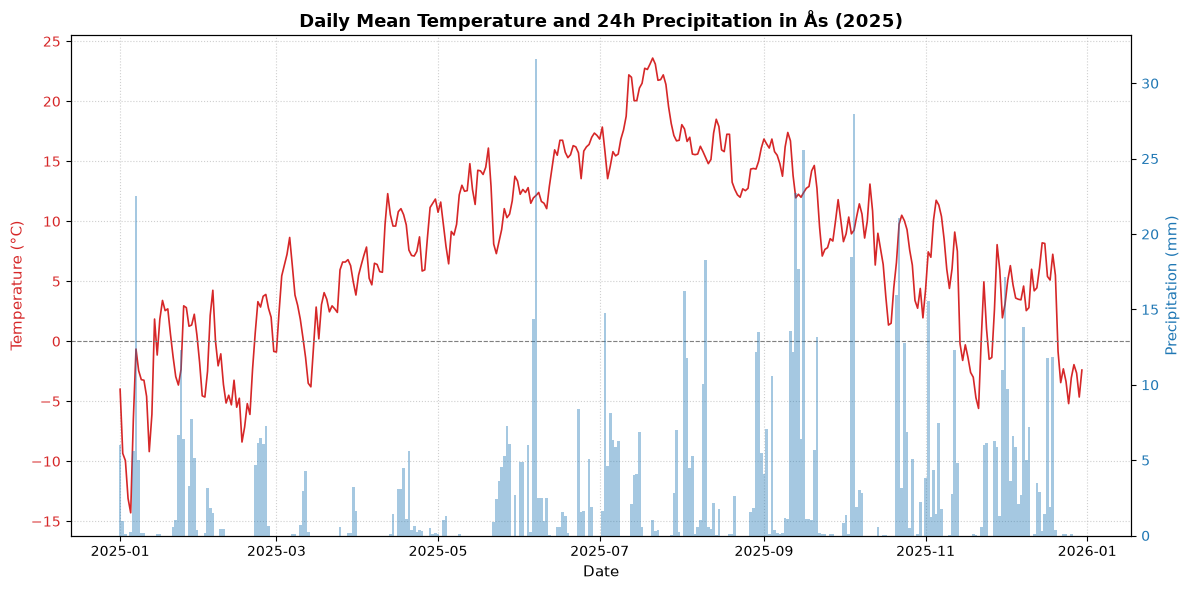

In [46]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Read the client ID from a local file
client_path = os.path.expanduser("~/Documents/client.txt")
with open(client_path, encoding="utf-8") as client_file:
    client_id = client_file.read().strip()

endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D),mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

r = requests.get(endpoint, params=parameters, auth=(client_id, ""), timeout=30)
response_data = r.json()

if r.status_code == 200:
    rows = []
    for entry in response_data.get("data", []):
        for observation in entry.get("observations", []):
            rows.append({
                "datetime": entry["referenceTime"],
                "element": observation["elementId"],
                "value": observation["value"],
            })

    if rows:
        df_long = pd.DataFrame(rows)
        df_long["datetime"] = pd.to_datetime(df_long["datetime"])

        df_pivot = (
            df_long.pivot_table(
                index="datetime",
                columns="element",
                values="value",
                aggfunc="mean",
            )
            .rename(columns={
                "mean(air_temperature P1D)": "temperature",
                "sum(precipitation_amount P1D)": "precipitation",
            })
            .reset_index()
            .sort_values("datetime")
        )

# Single plot setup with dual Y-axes
        fig, ax1 = plt.subplots(figsize=(12, 6))

        # Primary Axis (Left Y-Axis): Temperature Line
        color_temp = "tab:red"
        ax1.plot(
            df_pivot["datetime"],
            df_pivot["temperature"],
            color=color_temp,
            linewidth=1.2,
            label="Temperature",
        )
        ax1.axhline(0, color="gray", linestyle="--", linewidth=0.8)
        ax1.set_xlabel("Date", fontsize=11)
        ax1.set_ylabel("Temperature (°C)", color=color_temp, fontsize=11)
        ax1.tick_params(axis="y", labelcolor=color_temp)
        ax1.grid(True, linestyle=":", alpha=0.6)

        # Secondary Axis (Right Y-Axis): Precipitation Bars
        ax2 = ax1.twinx()
        color_precip = "tab:blue"
        ax2.bar(
            df_pivot["datetime"],
            df_pivot["precipitation"],
            color=color_precip,
            alpha=0.4,
            width=1.0,
            label="Precipitation",
        )
        ax2.set_ylabel("Precipitation (mm)", color=color_precip, fontsize=11)
        ax2.tick_params(axis="y", labelcolor=color_precip)

        plt.title("Daily Mean Temperature and 24h Precipitation in Ås (2025)", fontsize=13, fontweight="bold")
        fig.tight_layout()
        plt.show()

    else:
        print("The request succeeded, but returned no observations.")
else:
    error = response_data.get("error", {})
    print(f"Error {r.status_code}: {error.get('message', 'No error message provided')}")
    print(f"Reason: {error.get('reason', 'No reason provided')}")

Task 3: A 100 year summary of the temparature through 1925-2025, with the addition of a graph

=== Temperature Summary Statistics (1925 vs 2025) ===
       1925 Temperature (°C)  2025 Temperature (°C)
count             364.000000             364.000000
mean                5.310440               7.902747
std                 9.160347               7.526496
min               -20.700000             -15.500000
25%                -1.400000               2.850000
50%                 5.300000               8.400000
75%                12.425000              13.900000
max                24.300000              23.700000


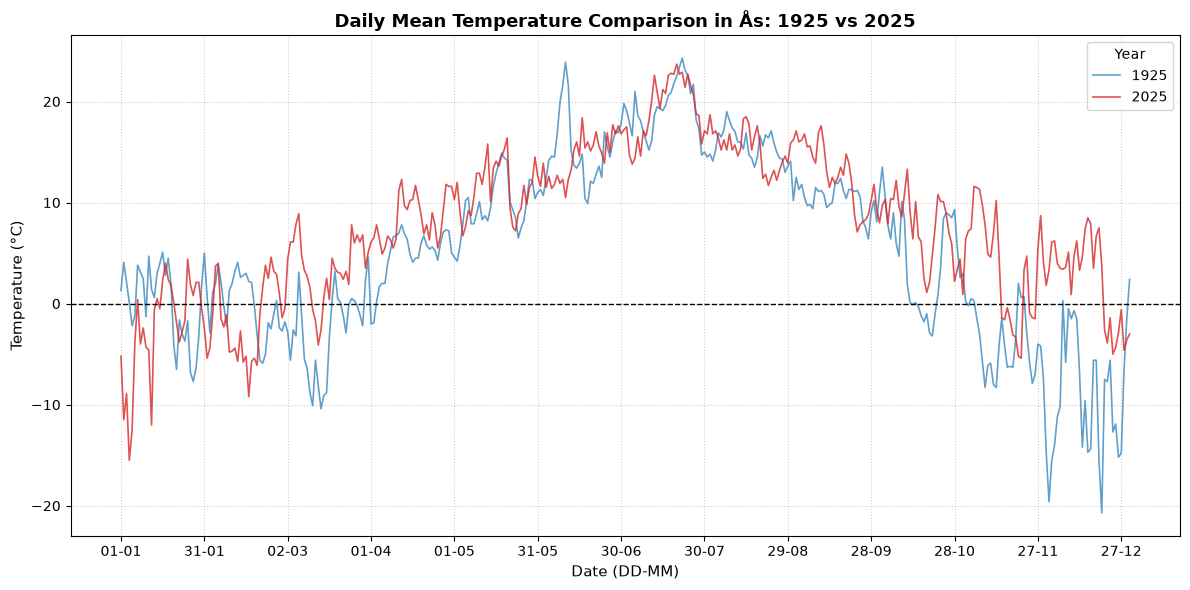

In [52]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Reading the client ID from a local file
client_path = os.path.expanduser("~/Documents/client.txt")
with open(client_path, encoding="utf-8") as client_file:
    client_id = client_file.read().strip()

endpoint = "https://frost.met.no/observations/v0.jsonld"


def fetch_temperature_data(year):
    """Helper function to fetch daily mean temperature for a specific year."""
    parameters = {
        "sources": "SN17850",
        "elements": "mean(air_temperature P1D)",
        "referencetime": f"{year}-01-01/{year}-12-31",
    }
    response = requests.get(
        endpoint, params=parameters, auth=(client_id, ""), timeout=30
    )

    if response.status_code == 200:
        rows = []
        response_data = response.json()
        for entry in response_data.get("data", []):
            for observation in entry.get("observations", []):
                rows.append({
                    "datetime": entry["referenceTime"],
                    f"temperature_{year}": observation["value"],
                })

        df = pd.DataFrame(rows)
        df["datetime"] = pd.to_datetime(df["datetime"])

        # Extract day-month (DD-MM) to align both years on the same X-axis
        df["day_of_year"] = df["datetime"].dt.strftime("%d-%m")
        return df[["day_of_year", f"temperature_{year}"]].drop_duplicates(
            "day_of_year"
        )
    else:
        print(f"Error fetching {year} data: {response.status_code}")
        return None


# Fetch observations for both years
df_1925 = fetch_temperature_data(1925)
df_2025 = fetch_temperature_data(2025)

if df_1925 is not None and df_2025 is not None:
    # Merge datasets on day of year
    df_comparison = pd.merge(df_1925, df_2025, on="day_of_year")

    # Generating summary statistics for both years
    summary_table = df_comparison[
        ["temperature_1925", "temperature_2025"]
    ].describe()
    summary_table.columns = ["1925 Temperature (°C)", "2025 Temperature (°C)"]

    print("=== Temperature Summary Statistics (1925 vs 2025) ===")
    print(summary_table)

    #Plotting Both Years on a Single Plot
    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(
        df_comparison["day_of_year"],
        df_comparison["temperature_1925"],
        color="tab:blue",
        alpha=0.7,
        linewidth=1.2,
        label="1925",
    )
    ax.plot(
        df_comparison["day_of_year"],
        df_comparison["temperature_2025"],
        color="tab:red",
        alpha=0.8,
        linewidth=1.2,
        label="2025",
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_ylabel("Temperature (°C)", fontsize=11)
    ax.set_xlabel("Date (DD-MM)", fontsize=11)
    ax.set_title(
        "Daily Mean Temperature Comparison in Ås: 1925 vs 2025",
        fontsize=13,
        fontweight="bold",
    )

    # Reduce X-axis tick frequency to avoid label overcrowding
    ax.set_xticks(df_comparison["day_of_year"][::30])
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(title="Year")

    plt.tight_layout()
    plt.show()
